In [39]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [40]:
df = pd.read_csv('ThreeChamb_Times.csv')

print(df)

    Group    CS+  Neutral    CS- Control
0       1  132.8     23.2  144.0       y
1       2    8.7     62.1  229.2       n
2       3    0.7     20.9  278.4       n
3       4    1.0     13.8  285.2       n
4       5   28.1    231.2   40.7       n
5       6  120.4     64.6  115.0       y
6       7    9.0    130.1  160.9       n
7       8   64.5     28.1  207.4       n
8       9  232.8     55.0   12.2       n
9      10   19.0    125.8  155.2       n
10     11   95.3     58.7  146.0       y
11     12  150.0     49.8  100.2       y
12     13  115.2     38.6  146.2       y
13     14  102.7     78.5  118.8       y
14     15  105.4     68.7  125.9       y
15     16   85.2     73.9  140.9       y


In [41]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
print(el)

CS-


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_52132/1866674919.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['CS+','Neutral','CS-'],fontsize=30)


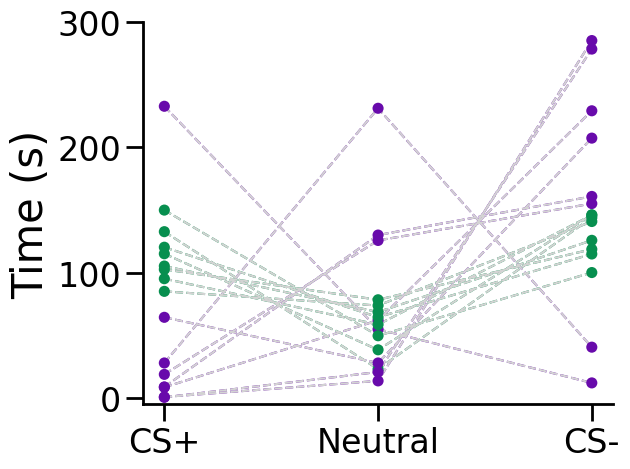

In [42]:
colors = [ '#078f4f',"#680aab"]


ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    jitter=0,
    palette=colors,
    size = 8
)



handles, labels = ax.get_legend_handles_labels()
l = plt.legend(handles[0:2], ["Mock", "SFC"], frameon=False, fontsize=18)
plt.legend().remove()


ax.set_xticklabels(['CS+','Neutral','CS-'],fontsize=30)


###START: CONNECT THE DOTS
df_list = df.values.tolist()

values_x = [0,1,2]

for el in df_list:
    if('y' in el):
        plt.plot(values_x,el[1:-1],color="#078f4f", linestyle='--')
    else:
        plt.plot(values_x,el[1:-1],color="#680aab", linestyle='--')
        
for el in df_list:
    if('y' in el):
        plt.plot(values_x,el[1:-1],color="lightgrey", linestyle='--')
    else:
        plt.plot(values_x,el[1:-1],color="lightgrey", linestyle='--')

###END: CONNECT THE DOTS


ax.set_xlabel("Compartments",fontsize=30)
ax.set_xlabel("",fontsize=30)
ax.set_ylabel("Time (s)",fontsize=30)

plt.title("Recall - Three Chamber Arena", fontsize=20,y=1.1)
plt.title("", fontsize=20,y=1.1)

plt.ylim([-5,300])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.tick_params(axis='both', which='major', direction='out',length=12, labelsize=24, width=2)



fig = ax.get_figure()
plt.tight_layout()
fig.tight_layout()
fig.savefig("ThreeChamb_Times_Aligned.jpg",dpi=600)
plt.savefig('ThreeChamb_Times_Aligned.eps', dpi=600, format='eps')
